# B1 · Meteorological data

In the PyPSA tutorials, the hourly capacity factors of solar PV (`solar_CF`) and wind (`wind_CF`) were given as input data. The goal of the atlite tutorials is to apply a **methodology to estimate** these capacity factors. The starting point is **meteorological data** (wind speed, solar radiation, temperature, ...), which [atlite](https://atlite.readthedocs.io) converts into hourly capacity factors with models of wind turbines and solar panels.

This first tutorial downloads the meteorological data (a *cutout*) and analyses the two resources: **wind** and **solar radiation** over peninsular Spain. Tutorials B2 and B3 apply the methodology to estimate the capacity factors of onshore wind and solar PV.

Based on the [atlite workshop](https://fneum.github.io/data-science-for-esm/dsesm/workshop-atlite/) of the course *Data Science for Energy System Modelling* (F. Neumann, TU Berlin).

## 0. Import the required modules

In [1]:
from pathlib import Path
from urllib.request import urlretrieve

import atlite
import cartopy.crs as ccrs
import cartopy.io.shapereader as shpreader
import geopandas as gpd
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import xarray as xr

# Colors of the carriers (same as in the PyPSA tutorials)
colors = {"solar": "gold", "wind": "steelblue"}

## 1. Download and load the cutout

A **cutout** is a NetCDF file with hourly weather data on a regular grid, for a region and a period. atlite can build cutouts from public datasets (it downloads the data itself), but this takes time. Here a ready-made cutout is used, from the Zenodo dataset [*ERA5–SARAH-3 Meteorological Cutouts for Renewable Energy Modelling with PyPSA-Spain*](https://doi.org/10.5281/zenodo.22745627) (CC BY 4.0):

- **Region**: Iberian Peninsula and nearby offshore areas.
- **Period**: one file per year, 1990–2020. Here, the year **2020**.
- **Resolution**: 0.3° × 0.3° (about 30 km), hourly.
- **Sources**: [ERA5](https://cds.climate.copernicus.eu) reanalysis (wind, temperature, ...) and [SARAH-3](https://wui.cmsaf.eu) satellite data (solar radiation). SARAH-3 radiation is only kept on land and up to 50 km from the coast; farther offshore it is missing (`NaN`).

The file is about 800 MB: it is downloaded only once, to the `data` folder. `atlite.Cutout` opens it; its summary shows the spatial extent (`x`: longitude, `y`: latitude), the resolution, the period and the available features.

In [2]:
url = "https://zenodo.org/records/22745628/files/iberia-2020-era5-sarah3.nc?download=1"
fn = Path("data/iberia-2020-era5-sarah3.nc")

if not fn.exists():
    fn.parent.mkdir(exist_ok=True)
    print(f"Downloading {fn.name} (about 800 MB)...")
    urlretrieve(url, fn)

cutout = atlite.Cutout(fn)
cutout

<Cutout "iberia-2020-era5-sarah3">
 x = -12.00 ⟷ 6.90, dx = 0.30
 y = 33.00 ⟷ 48.00, dy = 0.30
 time = 2020-01-01 ⟷ 2020-12-31, dt = h
 module = era5
 prepared_features = ['height', 'wind', 'influx', 'temperature', 'runoff']

The weather data are stored in `cutout.data`, an [xarray](https://docs.xarray.dev) `Dataset`: a collection of multi-dimensional arrays with labelled dimensions (`time`, `y`, `x`), a kind of multi-dimensional `pandas`. The main variables are:

- `wnd100m`: wind speed at 100 m above ground (m/s).
- `roughness`: surface roughness length (m), used to extrapolate the wind speed to other heights (tutorial B2).
- `influx_direct`, `influx_diffuse`: direct and diffuse solar radiation on a horizontal surface (W/m²). Their sum is the **global horizontal irradiance** (GHI).
- `temperature`: air temperature at 2 m (K), which reduces the efficiency of the solar panels (tutorial B3).

In [3]:
cutout.data

<xarray.Dataset> Size: 2GB
Dimensions:               (y: 51, x: 64, time: 8784)
Coordinates:
  * y                     (y) float64 408B 33.0 33.3 33.6 ... 47.4 47.7 48.0
    lat                   (y) float64 408B dask.array<chunksize=(51,), meta=np.ndarray>
  * x                     (x) float64 512B -12.0 -11.7 -11.4 ... 6.3 6.6 6.9
    lon                   (x) float64 512B dask.array<chunksize=(64,), meta=np.ndarray>
  * time                  (time) datetime64[ns] 70kB 2020-01-01 ... 2020-12-3...
Data variables: (12/15)
    height                (y, x) float32 13kB dask.array<chunksize=(51, 64), meta=np.ndarray>
    wnd100m               (time, y, x) float32 115MB dask.array<chunksize=(100, 51, 64), meta=np.ndarray>
    wnd_shear_exp         (time, y, x) float32 115MB dask.array<chunksize=(100, 51, 64), meta=np.ndarray>
    wnd_azimuth           (time, y, x) float32 115MB dask.array<chunksize=(100, 51, 64), meta=np.ndarray>
    roughness             (time, y, x) float32 115MB dask.array<chunksize=(100, 51, 64), meta=np.ndarray>
    influx_toa            (time, y, x) float64 229MB dask.array<chunksize=(100, 51, 64), meta=np.ndarray>
    ...                    ...
    solar_altitude        (time, y, x) float64 229MB dask.array<chunksize=(100, 51, 64), meta=np.ndarray>
    solar_azimuth         (time, y, x) float64 229MB dask.array<chunksize=(100, 51, 64), meta=np.ndarray>
    temperature           (time, y, x) float32 115MB dask.array<chunksize=(100, 51, 64), meta=np.ndarray>
    soil temperature      (time, y, x) float32 115MB dask.array<chunksize=(100, 51, 64), meta=np.ndarray>
    dewpoint temperature  (time, y, x) float32 115MB dask.array<chunksize=(100, 51, 64), meta=np.ndarray>
    runoff                (time, y, x) float32 115MB dask.array<chunksize=(100, 51, 64), meta=np.ndarray>
Attributes: (12/17)
    module:                           era5
    prepared_features:                ['runoff', 'temperature', 'wind', 'infl...
    chunksize_time:                   100
    dx:                               0.3
    dy:                               0.3
    GRIB_centre:                      ecmf
    ...                               ...
    sarah3_max_offshore_distance_km:  50.0
    sarah3_offshore_mask:             SARAH-3 values set to NaN over sea fart...
    coast_distance_method:            nearest land grid-cell centre great-cir...
    spatial_subset:                   longitude [-14.0, 7.0], latitude [32.0,...
    sarah3_source_file:               iberia-2020-sarah3-era5.nc
    sarah3_interpolation:             linear interpolation to cropped Europea...

## 2. Region: peninsular Spain

Country borders from [Natural Earth](https://www.naturalearthdata.com), downloaded by `cartopy` on first use. The shape of Spain is a `MultiPolygon`: the peninsula, the Balearic and Canary Islands, Ceuta, Melilla, ... Only the largest polygon, the **peninsula**, is kept.

atlite relates the region to the weather grid with the **indicator matrix** (`cutout.indicatormatrix`): for each region and grid cell, the share of the cell area that lies inside the region (between 0 and 1). Reshaped to the grid (`y`, `x`), it is used as `weights` to average over peninsular Spain.

In [4]:
shp = shpreader.natural_earth(resolution="10m", category="cultural", name="admin_0_countries")
spain = gpd.read_file(shp).set_index("ISO_A2_EH").loc[["ES"], "geometry"]

# Split the MultiPolygon into single polygons and keep the largest one (area computed in an equal-area projection)
parts = spain.explode()
region = gpd.GeoSeries([parts.iloc[parts.to_crs(3035).area.argmax()]], index=["Peninsular Spain"], crs=parts.crs)

# Indicator matrix: one row per region, one column per grid cell (in the order of cutout.grid)
indicator = cutout.indicatormatrix(region)

# Share of each grid cell inside the region, as a (y, x) array like the weather data
weights = xr.DataArray(indicator.sum(axis=0).A1.reshape(cutout.shape), coords=[cutout.coords["y"], cutout.coords["x"]])

print(f"Area of peninsular Spain: {region.to_crs(3035).area.iloc[0] / 1e6:,.0f} km²; grid cells (partly) inside: {int((weights > 0).sum())}")

Area of peninsular Spain: 494,246 km²; grid cells (partly) inside: 670


The cutout covers more than peninsular Spain: also Portugal, the sea, part of France and North Africa. The map shows the grid and the `weights` of the cells (green): 1 for cells fully inside peninsular Spain, between 0 and 1 for cells on the border or the coast.

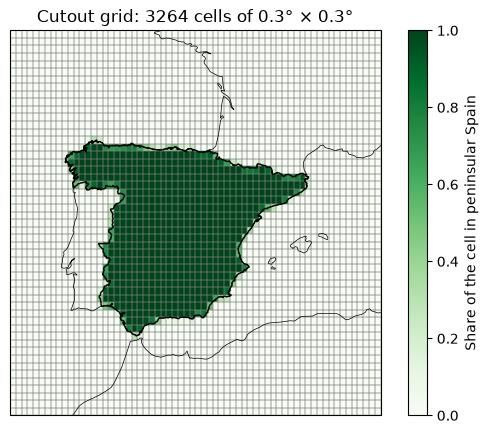

In [5]:
fig, ax = plt.subplots(1, 1, figsize=(7, 5), subplot_kw={"projection": ccrs.PlateCarree()})
weights.plot(ax=ax, cmap="Greens", vmin=0, vmax=1, cbar_kwargs={"label": "Share of the cell in peninsular Spain"})
cutout.grid.plot(ax=ax, edgecolor="grey", color="none", lw=0.3)
region.plot(ax=ax, edgecolor="black", color="none")
ax.coastlines(lw=0.5)
ax.set_extent(cutout.extent, crs=ccrs.PlateCarree())
ax.set_title(f"Cutout grid: {len(cutout.grid)} cells of {cutout.dx}° × {cutout.dy}°");

## 3. Wind

### Annual mean wind speed

Mean over the time dimension of each grid cell (a map). Wind speeds are much higher over the sea than over land (Atlantic, Gulf of Lion, Strait of Gibraltar).

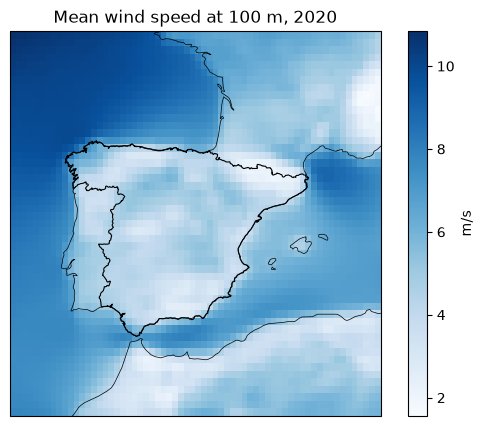

In [6]:
wnd100m = cutout.data["wnd100m"]

fig, ax = plt.subplots(1, 1, figsize=(7, 5), subplot_kw={"projection": ccrs.PlateCarree()})
wnd100m.mean("time").plot(ax=ax, cmap="Blues", cbar_kwargs={"label": "m/s"})
region.plot(ax=ax, edgecolor="black", color="none", lw=0.8)
ax.coastlines(lw=0.5)
ax.set_title("Mean wind speed at 100 m, 2020");

### Time series of the spatial mean

Mean over the grid cells of peninsular Spain in each hour, weighted by the share of each cell inside the region (`weights`). Over a whole year hourly values are too dense to read, so the weekly mean is plotted as well. The strongest winds come in autumn and winter, with the passing storms.

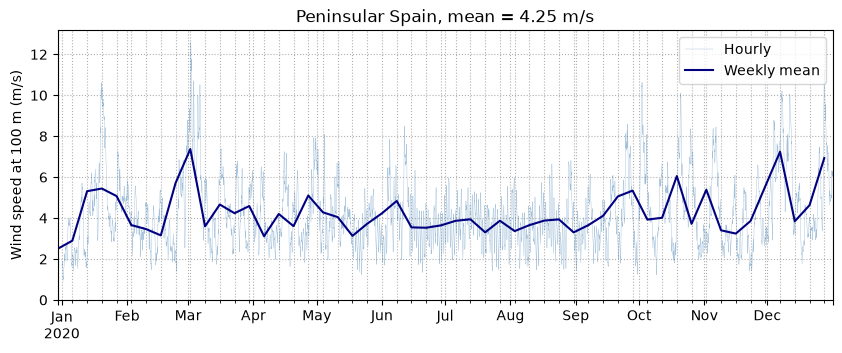

In [7]:
wnd100m_ts = wnd100m.weighted(weights).mean(["x", "y"]).to_pandas()

ax = wnd100m_ts.plot(figsize=(10, 3.5), color=colors["wind"], lw=0.3, alpha=0.5, label="Hourly")
wnd100m_ts.resample("W").mean().plot(ax=ax, color="navy", lw=1.5, label="Weekly mean")
ax.set_ylabel("Wind speed at 100 m (m/s)")
ax.set_xlabel("")
ax.set_ylim(bottom=0)
ax.grid(ls=":", which="both")
ax.legend(loc="upper right")
ax.set_title(f"Peninsular Spain, mean = {wnd100m_ts.mean():.2f} m/s");

### Spatial averaging smooths the variability

The wind in a single grid cell varies much more than the mean over the whole region: when the wind is calm in one place, it may blow somewhere else. The histogram compares the hourly wind speeds of one cell in the Ebro valley (Zaragoza) with those of the spatial mean. Aggregating wind farms over a large area makes their total output smoother.

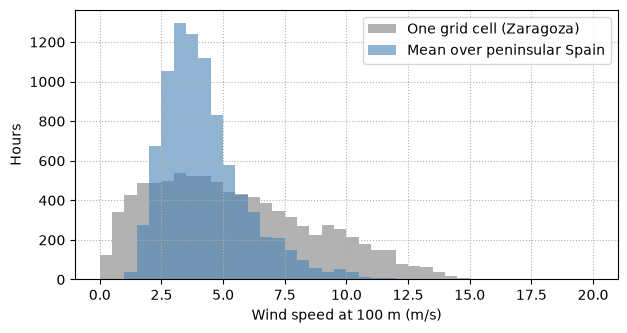

In [8]:
wnd100m_cell = wnd100m.sel(x=-0.9, y=41.65, method="nearest").to_pandas()  # grid cell closest to Zaragoza

ax = wnd100m_cell.plot.hist(bins=40, range=(0, 20), alpha=0.6, color="grey", figsize=(7, 3.5), label="One grid cell (Zaragoza)")
wnd100m_ts.plot.hist(ax=ax, bins=40, range=(0, 20), alpha=0.6, color=colors["wind"], label="Mean over peninsular Spain")
ax.set_xlabel("Wind speed at 100 m (m/s)")
ax.set_ylabel("Hours")
ax.grid(ls=":", which="both")
ax.legend();

## 4. Solar radiation

### Annual irradiation

The mean GHI (W/m²) multiplied by the hours of the year gives the **annual irradiation** (kWh/m²), the usual figure to compare solar resources. It increases towards the south. The white area is the open sea, where the SARAH-3 data are missing.

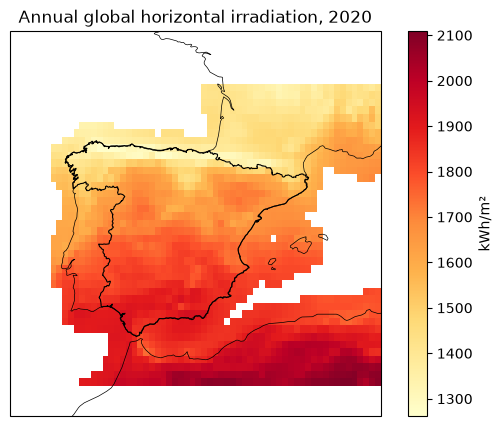

In [9]:
ghi = cutout.data["influx_direct"] + cutout.data["influx_diffuse"]
hours = len(cutout.coords["time"])  # 8784 h in 2020, a leap year

fig, ax = plt.subplots(1, 1, figsize=(7, 5), subplot_kw={"projection": ccrs.PlateCarree()})
(ghi.mean("time") * hours / 1e3).plot(ax=ax, cmap="YlOrRd", cbar_kwargs={"label": "kWh/m²"})
region.plot(ax=ax, edgecolor="black", color="none", lw=0.8)
ax.coastlines(lw=0.5)
ax.set_title("Annual global horizontal irradiation, 2020");

### Time series of the spatial mean

The radiation follows the seasons: the weekly mean in summer is about four to five times that in winter.

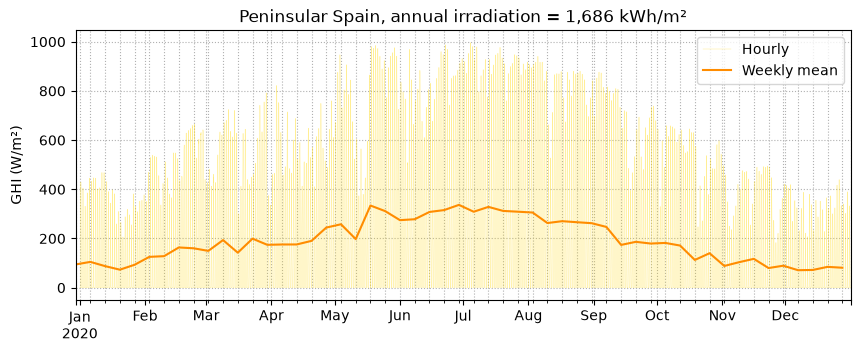

In [10]:
ghi_ts = ghi.weighted(weights).mean(["x", "y"]).to_pandas()

ax = ghi_ts.plot(figsize=(10, 3.5), color=colors["solar"], lw=0.3, alpha=0.5, label="Hourly")
ghi_ts.resample("W").mean().plot(ax=ax, color="darkorange", lw=1.5, label="Weekly mean")
ax.set_ylabel("GHI (W/m²)")
ax.set_xlabel("")
ax.grid(ls=":", which="both")
ax.legend(loc="upper right")
ax.set_title(f"Peninsular Spain, annual irradiation = {ghi_ts.sum() / 1e3:,.0f} kWh/m²");

### Spatial averaging and the variability of the radiation

Same comparison as for the wind: hourly GHI of the grid cell of Zaragoza and of the mean over peninsular Spain. Only daytime hours (mean GHI above 0) are included: at night the radiation is 0 everywhere. Unlike the wind, both distributions are very similar: most of the variability of the radiation comes from the day–night cycle and the seasons, which are the same over the whole region, and spatial averaging cannot remove it.

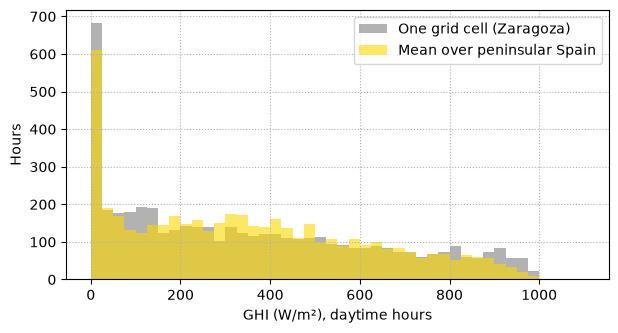

In [11]:
ghi_cell = ghi.sel(x=-0.9, y=41.65, method="nearest").to_pandas()  # grid cell closest to Zaragoza
daytime = ghi_ts > 0

ax = ghi_cell[daytime].plot.hist(bins=44, range=(0, 1100), alpha=0.6, color="grey", figsize=(7, 3.5), label="One grid cell (Zaragoza)")
ghi_ts[daytime].plot.hist(ax=ax, bins=44, range=(0, 1100), alpha=0.6, color=colors["solar"], label="Mean over peninsular Spain")
ax.set_xlabel("GHI (W/m²), daytime hours")
ax.set_ylabel("Hours")
ax.grid(ls=":", which="both")
ax.legend();

## 5. Wind and radiation in one summer week

The radiation follows a regular day–night cycle. The wind is less regular: it has a daily pattern too, but its level changes from one day to another with the passing weather systems.

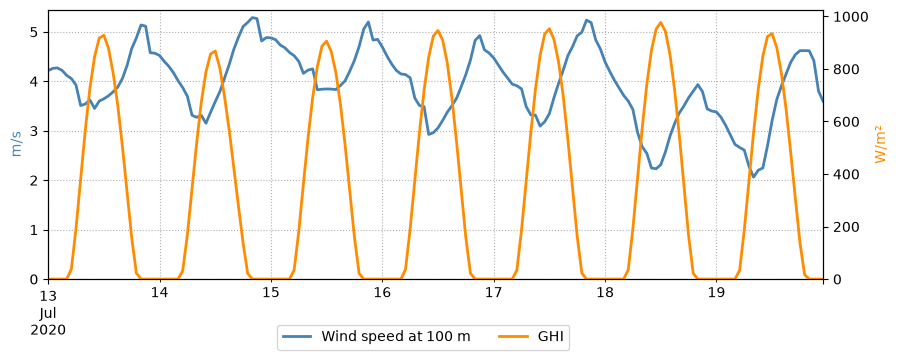

In [12]:
week = slice("2020-07-13", "2020-07-19")  # summer week used in the zoomed plots

fig, ax1 = plt.subplots(figsize=(10, 3.5))
ax2 = ax1.twinx()  # second y-axis for the radiation

wnd100m_ts.loc[week].plot(ax=ax1, color=colors["wind"], lw=2, label="Wind speed at 100 m")
ghi_ts.loc[week].plot(ax=ax2, color="darkorange", lw=2, label="GHI")
ax1.set_ylabel("m/s", color=colors["wind"])
ax2.set_ylabel("W/m²", color="darkorange")
ax1.set_ylim(bottom=0)
ax2.set_ylim(bottom=0)
ax1.set_xlabel("")
ax1.grid(ls=":", which="both")
fig.legend(loc="upper center", bbox_to_anchor=(0.5, 0), ncol=2);

## 6. Final remarks

- Wind and radiation have opposite seasonal patterns over peninsular Spain. What does this mean for a power system with both wind and solar PV?
- Compare the wind speed over land with that over the sea. Why is offshore wind attractive despite its higher costs?
- Why does spatial averaging reduce the variability of the wind much more than that of the radiation? (Hint: what drives the variability of each resource, and at which spatial scale?)
- Pick another grid cell (for example, in Galicia or in Andalusia) and compare its wind and radiation with the spatial mean.
- The Zenodo dataset includes cutouts from 1990 to 2020. How much could the annual mean wind speed or irradiation change from one year to another?